# Librerias

In [253]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import geopandas as gpd
import simpledbf as dbf
import os
import zipfile 
import rioxarray 
from rioxarray.merge import merge_arrays

import rasterio as rio
import rasterio.plot as rioplot
from rasterio.mask import mask
from rasterio.features import rasterize
from rasterio.enums import Resampling
from rasterio.warp import reproject

import osmnx as ox

from rasterstats import zonal_stats



# Distribución de población
Esta sección se centra en el análisis de la distribución de la población. Contiene subsecciones para descargar datos de GHSL, cargar variables del INEGI y distribuir estas variables de población según la superficie construida, lo que permite un análisis detallado de la demografía en el contexto urbano.

In [116]:
# Directorios y rutas de información 
GHSL_FOLDER_PATH = '../data/input/ghsl'
if not os.path.exists(GHSL_FOLDER_PATH):
    os.makedirs(GHSL_FOLDER_PATH)

SCINCE_FOLDER_PATH = '../data/input/scince'
if not os.path.exists(SCINCE_FOLDER_PATH):
    os.makedirs(SCINCE_FOLDER_PATH)

POP_DISTRIBUTION_OUTPUT_FOLDER = '../data/output/'
if not os.path.exists(POP_DISTRIBUTION_OUTPUT_FOLDER):
    os.makedirs(POP_DISTRIBUTION_OUTPUT_FOLDER)

# Los archivos de manzanas fueron descargados de INEGI y procesados en QGIS para obtener la información de población por manzana para cada municipio.
MANZANAS_FOLDER_PATH = '../data/input/manzanas'
if not os.path.exists(MANZANAS_FOLDER_PATH):
    os.makedirs(MANZANAS_FOLDER_PATH)


In [118]:
# Variable objetivo de INEGI
target_attributes = "POB1"
target_attributes_names = "Población total"

# Clave del municipio considerado para el análisis de brechas de servicios. Es un código de 5 dígitos, donde los dos primeros dígitos corresponden al estado y los tres últimos al municipio.
study_area = '07009'


In [119]:
# Cargar información de municipios de México
municipios = gpd.read_file('../data/input/scince/municipal.shp')
municipios.head(5)

,CVEGEO,NOM_ENT,NOMGEO,POB1,POB2,POB2_R,POB4,POB4_R,POB5,POB5_R,...,POB121,POB121_R,POB122,POB122_R,POB123,POB123_R,POB124,POB124_R,OID,geometry
0,01001,Aguascalientes,Aguascalientes,948990.0,44372.0,4.7,48767.0,5.1,97947.0,10.3,...,8177.0,0.9,5230.0,0.6,2817.0,0.3,2180.0,0.2,1,"POLYGON ((2489072.504 1115771.584, 2489352.774..."
1,01002,Aguascalientes,Asientos,51536.0,3170.0,6.2,3342.0,6.5,6605.0,12.8,...,425.0,0.8,285.0,0.6,217.0,0.4,197.0,0.4,2,"POLYGON ((2494680.261 1141224.505, 2494749.948..."
2,01003,Aguascalientes,Calvillo,58250.0,3159.0,5.4,3530.0,6.1,6748.0,11.6,...,723.0,1.2,529.0,0.9,317.0,0.5,285.0,0.5,3,"POLYGON ((2429607.454 1120262.254, 2429071.902..."
3,01004,Aguascalientes,Cosío,17000.0,1032.0,6.1,1062.0,6.2,2086.0,12.3,...,151.0,0.9,97.0,0.6,51.0,0.3,62.0,0.4,4,"POLYGON ((2470517.824 1155028.588, 2470552.248..."
4,01005,Aguascalientes,Jesús María,129929.0,6945.0,5.4,7998.0,6.2,15597.0,12.0,...,826.0,0.6,530.0,0.4,311.0,0.2,246.0,0.2,5,"POLYGON ((2465526.729 1114740.466, 2465752.546..."


Población total: 41135.0


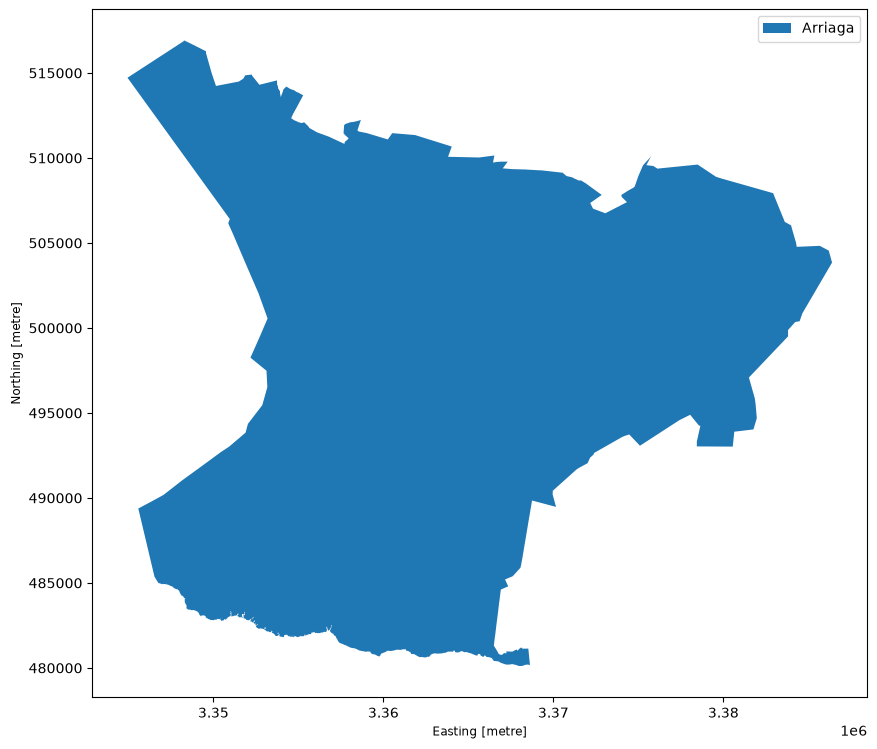

In [49]:
# Filtrar el municipio de estudio
sa_gpd = municipios[municipios['CVEGEO'].isin([study_area])]
sa_gpd.plot(column='NOMGEO', legend=True, figsize=(10, 10))

pob_municipal = sa_gpd['POB1'].values[0]
print("Población total: {}".format(pob_municipal))

In [120]:
manzana_file_paths = os.path.join(MANZANAS_FOLDER_PATH, f"CVEMUN_{study_area}.gpkg")
manzana_gpd = gpd.read_file(manzana_file_paths)

# Estimar la población total por manzanas y compararla con la población total del municipio
pob_manzanas = manzana_gpd['POB1'].sum()
print("Población total por manzanas: {}".format(pob_manzanas))

Población total por manzanas: 28908.0


In [51]:
pob_urbana_ratio = 100 * (pob_manzanas / pob_municipal)
print("Proporción de población por manzanas: {}".format(pob_urbana_ratio))

Proporción de población por manzanas: 70.2759207487541


## GHSL Downloader
Descarga de información de GHSL

In [53]:
# Cargar malla de GHSL 
ghsl_grid = gpd.read_file('../data/input/ghsl/GHSL2_0_MWD_L1_tile_schema_land.shp')
ghsl_grid.head(5)

,tile_id,left,top,right,bottom,geometry
0,R10_C10,-9041000,0,-8041000,-1000000,"POLYGON ((-9041000 0, -8041000 0, -8041000 -10..."
1,R10_C11,-8041000,0,-7041000,-1000000,"POLYGON ((-8041000 0, -7041000 0, -7041000 -10..."
2,R10_C12,-7041000,0,-6041000,-1000000,"POLYGON ((-7041000 0, -6041000 0, -6041000 -10..."
3,R10_C13,-6041000,0,-5041000,-1000000,"POLYGON ((-6041000 0, -5041000 0, -5041000 -10..."
4,R10_C14,-5041000,0,-4041000,-1000000,"POLYGON ((-5041000 0, -4041000 0, -4041000 -10..."


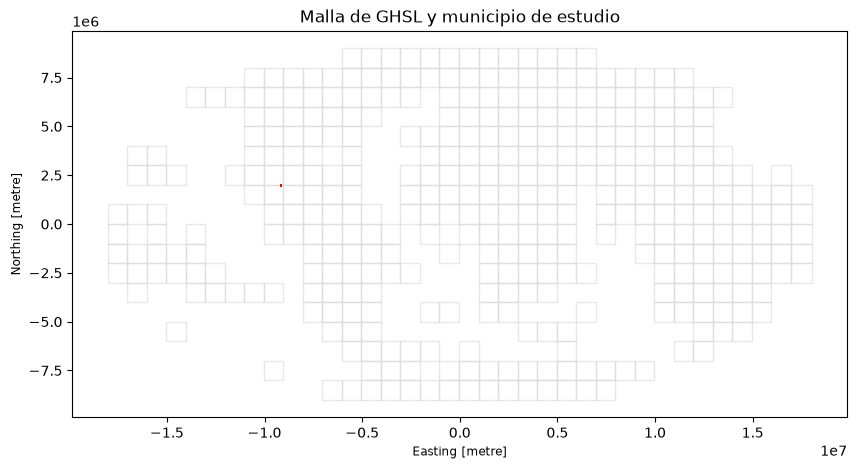

In [71]:
# Proyectar la malla de GHSL al sistema de coordenadas del municipio
sa_gpd_projected = sa_gpd.to_crs(ghsl_grid.crs)

fig, ax = plt.subplots(figsize=(10, 10))
ghsl_grid.plot(ax=ax, color='white', edgecolor='lightgrey', alpha=0.5)
sa_gpd_projected.plot(ax=ax, color='red', edgecolor='red')
plt.title('Malla de GHSL y municipio de estudio')
plt.show()

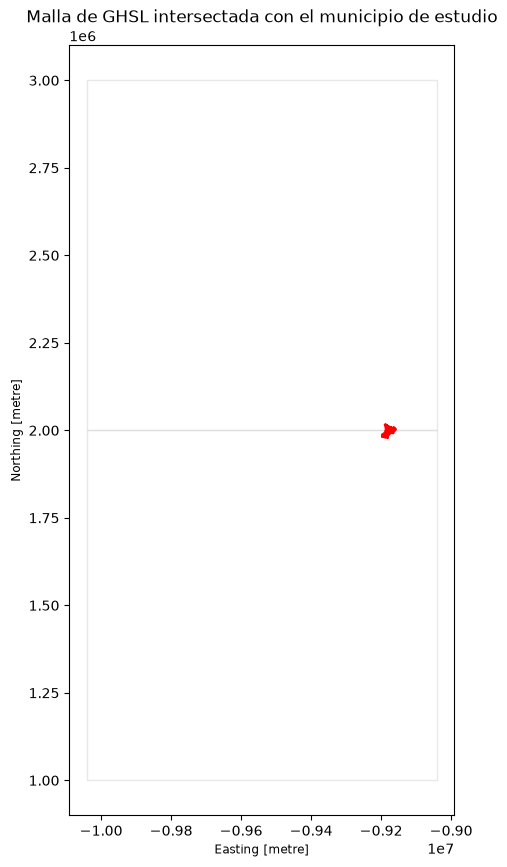

In [75]:
# Seleccionq todas los cuadrantes de la malla de GHSL que intersectan con el municipio de estudio
ghsl_instersected = ghsl_grid.sjoin(sa_gpd_projected, predicate = 'intersects') 
ghsl_instersected

fig, ax = plt.subplots(figsize=(10, 10))
ghsl_instersected.plot(ax=ax, color='white', edgecolor='lightgrey', alpha=0.5)
sa_gpd_projected.plot(ax=ax, color='red', edgecolor='red')
plt.title('Malla de GHSL intersectada con el municipio de estudio')
plt.show()

In [78]:
dataset = "GHS_BUILT_S"
# Define the GHSL URL structure
#base_url <- "https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_C_GLOBE_R2023A/GHS_BUILT_C_MSZ_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/"
base_url = "https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_S_GLOBE_R2023A/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/"

#filename_prefix <- "GHS_BUILT_C_MSZ_E2018_GLOBE_R2023A_54009_10_V1_0_"
filename_prefix = "GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_"

num_features = len(ghsl_instersected)
num_features

# Create destination directory using os


# Iterate through the GeoDataFrame rows
for i, (index, current_feature) in enumerate(ghsl_instersected.iterrows(), start=1):
    
    # Extract the tile ID
    tile_id = current_feature['tile_id']
    
    print(f"\n--- Processing feature # {i} : Tile ID is {tile_id} ---")
    
    # A. Construct Paths
    tile_destination_directory = GHSL_FOLDER_PATH
    
    # Filename and URL strings
    zip_filename = f"{filename_prefix}{tile_id}.zip"
    full_url = f"{base_url}{zip_filename}"
    
    # Use os.path to build the output path
    full_dest_file_path = os.path.join(tile_destination_directory, zip_filename)
    
    # B. Create Destination Folder
    if not os.path.exists(tile_destination_directory):
        os.makedirs(tile_destination_directory, exist_ok=True)
        print(f"Created destination folder at: {tile_destination_directory}")
    else:
        print(f"Destination folder already exists at: {tile_destination_directory}")
    
    # C. Download File using os.system
    if os.path.exists(full_dest_file_path):
        print(f"File already exists. Skipping download for: {zip_filename}")
    else:
        print(f"Starting download of: {full_url}")
        print(f"Saving to: {full_dest_file_path}")
        
        # Executes curl via os.system (mirrors R's libcurl option)
        exit_code = os.system(f'curl -o "{full_dest_file_path}" "{full_url}"')
        
        if exit_code == 0:
            print("Download complete!")
        else:
            print(f"Download failed for URL: {full_url}")


--- Processing feature # 1 : Tile ID is R7_C9 ---
Destination folder already exists at: ../data/input/ghsl
Starting download of: https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_S_GLOBE_R2023A/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
Saving to: ../data/input/ghsl\GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
Download complete!

--- Processing feature # 2 : Tile ID is R8_C9 ---
Destination folder already exists at: ../data/input/ghsl
Starting download of: https://jeodpp.jrc.ec.europa.eu/ftp/jrc-opendata/GHSL/GHS_BUILT_S_GLOBE_R2023A/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10/V1-0/tiles/GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip
Saving to: ../data/input/ghsl\GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip
Download complete!


In [86]:
# D. Identificar y descomprimir todos los archivos ZIP de GHSL_FOLDER_PATH
zip_file_paths = [
    os.path.join(GHSL_FOLDER_PATH, filename)
    for filename in os.listdir(GHSL_FOLDER_PATH)
    if filename.lower().endswith(".zip")
    and os.path.isfile(os.path.join(GHSL_FOLDER_PATH, filename))
]

if not zip_file_paths:
    print(f"No se encontraron archivos ZIP en: {GHSL_FOLDER_PATH}")
else:
    print(f"Se encontraron {len(zip_file_paths)} archivos ZIP:")
    for zip_file_path in zip_file_paths:
        print(f"- {os.path.basename(zip_file_path)}")

    for zip_file_path in zip_file_paths:
        try:
            with zipfile.ZipFile(zip_file_path, "r") as zip_ref:
                zip_ref.extractall(GHSL_FOLDER_PATH)
            print(f"Descomprimido: {os.path.basename(zip_file_path)}")
        except zipfile.BadZipFile:
            print(f"ERROR: El archivo no es un ZIP válido: {zip_file_path}")

Se encontraron 2 archivos ZIP:
- GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
- GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip
Descomprimido: GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R7_C9.zip
Descomprimido: GHS_BUILT_S_E2018_GLOBE_R2023A_54009_10_V1_0_R8_C9.zip


## Distribución de población urbana y no-urbana


In [179]:
import os
import numpy as np
import rasterio
from rasterio.mask import mask
from rasterio.merge import merge

# 1. Retrieve all .tif file paths dynamically from GHSL_FOLDER_PATH
# 1. Retrieve all .tif file paths dynamically from GHSL_FOLDER_PATH
tif_files = [
    os.path.join(GHSL_FOLDER_PATH, f)
    for f in os.listdir(GHSL_FOLDER_PATH)
    if f.endswith(".tif")
]

cropped_datasets = []

# 2. Iterate through retrieved file paths, open with rasterio, and clip
for fp in tif_files:
    with rasterio.open(fp) as src:
        # Ensure study area vector CRS matches the current tile CRS
        sa_proj = (
            sa_gpd_projected.to_crs(src.crs)
            if sa_gpd_projected.crs != src.crs
            else sa_gpd_projected
        )

        try:
            # Clip raster extent to study area geometries
            out_image, out_transform = mask(
                src, 
                sa_proj.geometry, 
                crop=True, 
                nodata=src.nodata
            )

            # Check if there are valid (non-nodata) pixels in the clipped image
            if src.nodata is not None:
                has_data = np.any(out_image != src.nodata)
            else:
                has_data = np.any(~np.isnan(out_image))

            if has_data:
                # Open a MemoryFile to hold the clipped dataset in RAM so it can be merged
                memfile = rasterio.MemoryFile()
                out_meta = src.meta.copy()
                out_meta.update({
                    "height": out_image.shape[1],
                    "width": out_image.shape[2],
                    "transform": out_transform
                })

                dataset = memfile.open(**out_meta)
                dataset.write(out_image)
                cropped_datasets.append(dataset)

        except (ValueError, Exception):
            # Skip tile if it does not geographically overlap
            continue

# 3. Mosaic overlapping tiles and save to GeoTIFF
if cropped_datasets:
    # Merge all clipped datasets into one array
    mosaic_array, mosaic_transform = merge(cropped_datasets)

    # Copy profile/metadata from the first clipped tile and update dimensions
    output_meta = cropped_datasets[0].meta.copy()
    output_meta.update({
        "driver": "GTiff",
        "height": mosaic_array.shape[1],
        "width": mosaic_array.shape[2],
        "transform": mosaic_transform,
        "compress": "deflate"
    })

    # Save directly to disk
    output_mosaic_path = os.path.join(GHSL_FOLDER_PATH, "ghsl_study_area_mosaic.tif")
    with rasterio.open(output_mosaic_path, "w", **output_meta) as dest:
        dest.write(mosaic_array)

    # Close temporary in-memory datasets
    for ds in cropped_datasets:
        ds.close()

    print(f"Found {len(tif_files)} files. Merged {len(cropped_datasets)} overlapping tiles.")
    print(f"Mosaic successfully saved to: {output_mosaic_path}")
else:
    print("No overlapping tiles found for the study area. No mosaic created.")

Found 3 files. Merged 3 overlapping tiles.
Mosaic successfully saved to: ../data/input/ghsl\ghsl_study_area_mosaic.tif


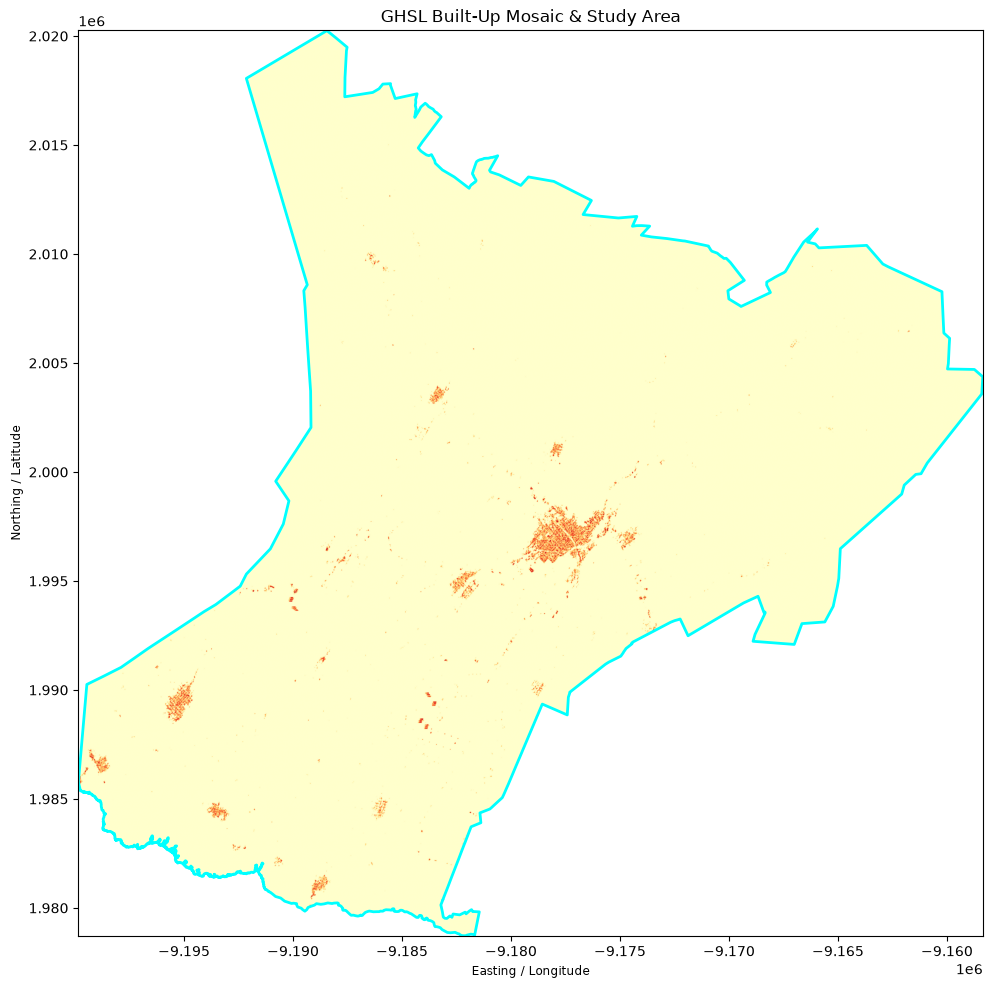

In [ ]:
# Plot the resulting mosaic and the study area boundary polygon
# 1. Open raster using rasterio
with rio.open(output_mosaic_path) as src:
    # 2. Ensure study area CRS matches the raster CRS
    sa_proj = sa_gpd_projected.to_crs(src.crs) if sa_gpd_projected.crs != src.crs else sa_gpd_projected

    # 3. Set up Matplotlib figure
    fig, ax = plt.subplots(figsize=(10, 10))

    # 4. Plot the raster mosaic using rasterio's show helper
    show(src, ax=ax, cmap="YlOrRd")

    # 5. Overlay the study area boundary polygon
    sa_proj.plot(
        ax=ax, 
        facecolor="none",      # Transparent interior so raster is visible
        edgecolor="cyan",      # High-contrast outline color
        linewidth=2, 
        label="Study Area"
    )

    # 6. Format plot axes and layout
    ax.set_title("GHSL Built-Up Mosaic & Study Area")
    ax.set_xlabel("Easting / Longitude")
    ax.set_ylabel("Northing / Latitude")
    plt.tight_layout()
    plt.show()

Raster successfully saved to: ../data/output/rural_population_distribution_07009.tif


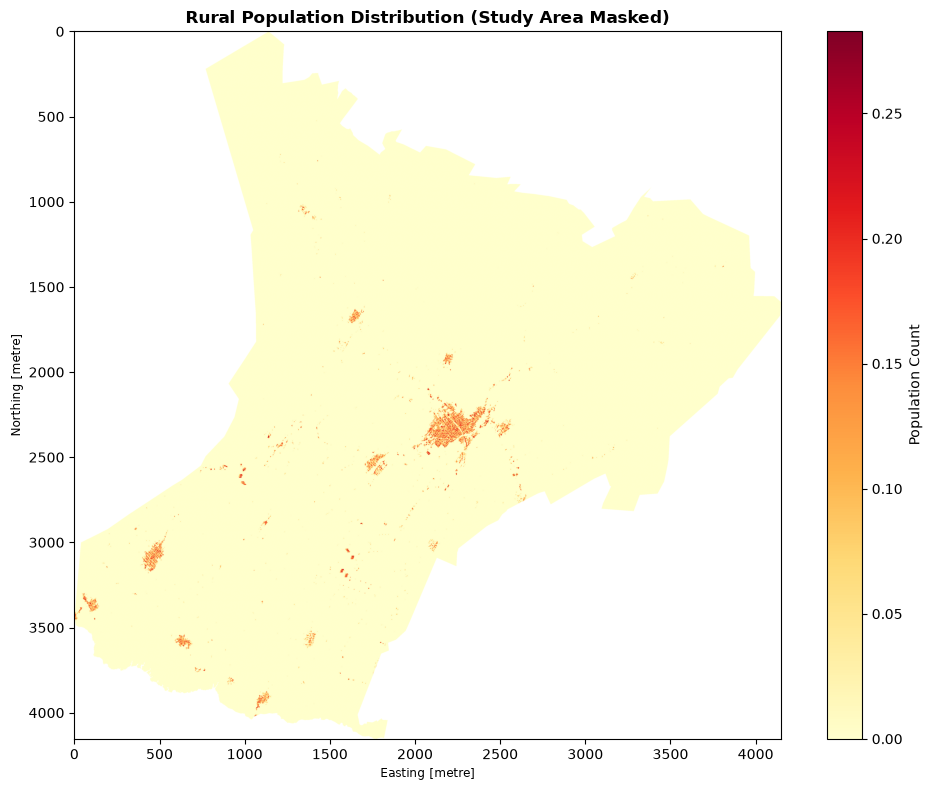

In [212]:
from rasterio.features import geometry_mask

# Crear una capa de ceros para la población por manzana, con el mismo sistema de coordenadas que la malla de GHSL
with rio.open(output_mosaic_path) as src:
    raster_transform = src.transform
    raster_shape = (src.height, src.width)
    raster_crs = src.crs
    final_mosaic_array = src.read(1)

    # 1. FIX: Ensure study area vector CRS matches the raster CRS explicitly
    sa_proj = sa_gpd_projected.to_crs(raster_crs) if sa_gpd_projected.crs != raster_crs else sa_gpd_projected
    manzana_proj = manzana_gpd.to_crs(raster_crs) if manzana_gpd.crs != raster_crs else manzana_gpd

   # Creates True outside geometries, False inside
    is_outside_manzanas = geometry_mask(
        manzana_gpd.geometry,
        out_shape=raster_shape,
        transform=raster_transform,
        invert=False
    )

    # Convert boolean mask to float (0 inside, NaN outside)
    # Tricky ~ (NOT) operator inverts the boolean mask, so that pixels inside manzanas are 0 and outside are NaN  
    zero_mask_array = np.where(~is_outside_manzanas, 0.0, np.nan)

    # 4. Create study area boundary mask (1 inside study area, NaN outside)
    sa_shapes = ((geom, 1) for geom in sa_proj.geometry)
    sa_mask_array = rasterize(
        shapes=sa_shapes,
        out_shape=raster_shape,
        transform=raster_transform,
        fill=np.nan,
        dtype=np.float32,
    )

    # 5. Stamp zeros onto original raster (mask out urban manzanas)
    rural_pixels = np.where(np.isnan(zero_mask_array), final_mosaic_array, zero_mask_array)

    # 6. Apply study area mask (keep pixels inside study area, set rest to NaN)
    rural_pixels = rural_pixels * sa_mask_array

    # 7. Calculate population distribution
    rural_population = pob_municipal - pob_manzanas
    total_sum = np.nansum(rural_pixels)
    rural_dist = rural_pixels / total_sum

    # 8. Final masked population raster
    rural_pop_dist = rural_dist * rural_population
    # 2. Save the array to disk
    rural_distribution_path = os.path.join(POP_DISTRIBUTION_OUTPUT_FOLDER, f"rural_population_distribution_{study_area}.tif")

    # 1. Update the metadata from the original raster source
    output_profile = src.profile.copy()
    output_profile.update({
        "dtype": "float32",
        "count": 1,
        "nodata": np.nan,
        "compress": "deflate"
    })
    with rio.open(rural_distribution_path, "w", **output_profile) as destination:
        destination.write(rural_pop_dist.astype(np.float32), 1)

    print(f"Raster successfully saved to: {rural_distribution_path}")
    


    # 9. Plot results
    fig, ax = plt.subplots(figsize=(10, 8))

    im = show(
        rural_pop_dist,
        transform=raster_transform,
        ax=ax,
        cmap="YlOrRd",
        title="Rural Population Distribution (Study Area Masked)",
    )

    # Overlay study area boundary polygon
    sa_proj.plot(
        ax=ax,
        facecolor="none",
        edgecolor="black",
        linewidth=1.5,
        linestyle="--",
        label="Study Area Boundary"
    )

    # Add colorbar
    image_hidden = ax.imshow(rural_pop_dist, cmap="YlOrRd")
    fig.colorbar(image_hidden, ax=ax, label="Population Count")

    plt.tight_layout()
    plt.show()

In [203]:
# Distribuir la población urbana de cada manzana en proporción a la superficie construida.
target_attributes_list = [target_attributes] if isinstance(target_attributes, str) else list(target_attributes)
blocks = manzana_gpd.loc[manzana_gpd.geometry.notna() & ~manzana_gpd.geometry.is_empty].copy()

if not target_attributes_list:
    raise ValueError("target_attributes debe contener al menos un atributo.")
missing_attributes = [attribute for attribute in target_attributes_list if attribute not in blocks.columns]
if missing_attributes:
    raise KeyError(f"No se encontraron atributos en manzana_gpd: {missing_attributes}")

with rio.open(output_mosaic_path) as src:
    blocks_raster_crs = blocks.to_crs(src.crs) if blocks.crs != src.crs else blocks
    cropped_raster, cropped_transform = mask(
        src,
        blocks_raster_crs.geometry,
        crop=True,
        filled=False,
    )
    builtup = np.ma.filled(cropped_raster[0].astype(np.float64), np.nan)

    block_shapes = (
        (geometry, block_id)
        for block_id, geometry in enumerate(blocks_raster_crs.geometry, start=1)
    )
    block_id_raster = rasterize(
        block_shapes,
        out_shape=builtup.shape,
        transform=cropped_transform,
        fill=0,
        dtype="int32",
    )

    valid_pixels = (block_id_raster > 0) & np.isfinite(builtup)
    builtup_totals = np.bincount(
        block_id_raster[valid_pixels],
        weights=builtup[valid_pixels],
        minlength=len(blocks) + 1,
    )
    allocated_rasters = []

    print("--- Iniciando la distribución de población urbana ---")
    for attribute in target_attributes_list:
        print(f"  -> Distribuyendo {attribute}...")
        block_values = pd.to_numeric(blocks[attribute], errors="coerce").to_numpy(dtype=float)
        missing_values = ~np.isfinite(block_values)
        if missing_values.any():
            print(f"     {missing_values.sum()} valores no numéricos o vacíos se tratarán como 0.")
            block_values[missing_values] = 0

        values_by_id = np.zeros(len(blocks) + 1, dtype=np.float64)
        values_by_id[1:] = block_values
        pixel_totals = builtup_totals[block_id_raster]
        allocatable = valid_pixels & (pixel_totals > 0)
        distributed = np.zeros(builtup.shape, dtype=np.float64)
        distributed[allocatable] = (
            values_by_id[block_id_raster[allocatable]]
            * builtup[allocatable]
            / pixel_totals[allocatable]
        )

        target_total = block_values.sum()
        distributed_total = distributed.sum()
        if distributed_total != 0:
            distributed *= target_total / distributed_total
        elif target_total != 0:
            print(f"     Advertencia: {attribute} no se pudo asignar porque no hay píxeles construidos válidos.")

        allocated_rasters.append(distributed.astype(np.float32))
        print(f"     Total asignado: {distributed.sum():.2f} (total de manzanas: {target_total:.2f})")

    urban_pop_dist = np.stack(allocated_rasters)
    urban_distribution_path = os.path.join(
        POP_DISTRIBUTION_OUTPUT_FOLDER,
        f"urban_population_distribution_{study_area}.tif",
    )
    output_profile = src.profile.copy()
    output_profile.update(
        driver="GTiff",
        height=builtup.shape[0],
        width=builtup.shape[1],
        transform=cropped_transform,
        count=len(target_attributes_list),
        dtype="float32",
        nodata=None,
        compress="deflate",
    )
    with rio.open(urban_distribution_path, "w", **output_profile) as destination:
        for band_number, attribute in enumerate(target_attributes_list, start=1):
            destination.write(urban_pop_dist[band_number - 1], band_number)
            destination.set_band_description(band_number, attribute)

print(f"Distribución urbana guardada en: {urban_distribution_path}")

--- Iniciando la distribución de población urbana ---
  -> Distribuyendo POB1...
     Total asignado: 28908.00 (total de manzanas: 28908.00)
Distribución urbana guardada en: ../data/output/urban_population_distribution_07009.tif


In [229]:

# B. Crop and Mask to Municipality
with rio.open(urban_distribution_path) as src:
    # Perform mask operation (crop=True crops raster extent to vector bounding box)
    masked_data, out_transform = mask(
        dataset=src,
        shapes=sa_gpd_projected.geometry,
        crop=True,  # Set to False to retain original raster extent
        nodata=np.nan,
    )

    # Convert 3D band array (1, height, width) to 2D
    urban_pop_dist_masked = masked_data[0]

In [ ]:
# Revisar raster final de distribución urbana
with rio.open(urban_distribution_path) as src:
    # 1. Leer la primera banda como arreglo numérico (convertido a float para manejar NaN)
    urban_dist_array = src.read(1).astype(np.float32)

    # 2. Reemplazar valor NoData con NaN si existe
    if src.nodata is not None:
        urban_dist_array[urban_dist_array == src.nodata] = np.nan

    # 3. Imprimir metadatos principales
    print("=== Metadatos del Raster Urbano ===")
    print(f"Dimensiones (filas, columnas): {src.height} x {src.width}")
    print(f"Sistema de Coordenadas (CRS):  {src.crs}")
    print(f"Resolución de pixel:           {src.res}")
    print(f"Extensión espacial (Bounds):   {src.bounds}")
    print(f"Suma total de población:       {np.nansum(urban_dist_array):,.2f}")
    print(
        f"Rango de valores:              Min = {np.nanmin(urban_dist_array):.4f}, Max = {np.nanmax(urban_dist_array):.4f}"
    )


=== Metadatos del Raster Urbano ===
Dimensiones (filas, columnas): 1112 x 2233
Sistema de Coordenadas (CRS):  ESRI:54009
Resolución de pixel:           (10.0, 10.0)
Extensión espacial (Bounds):   BoundingBox(left=-9196280.0, bottom=1988380.0, right=-9173950.0, top=1999500.0)
Suma total de población:       28,908.00
Rango de valores:              Min = 0.0000, Max = 29.0886


In [220]:
# Revisar raster final de distribución rural
with rio.open(rural_distribution_path) as src:
    # 1. Leer la primera banda como arreglo numérico (convertido a float para manejar NaN)
    rural_dist_array = src.read(1).astype(np.float32)

    # 2. Reemplazar valor NoData con NaN si existe
    if src.nodata is not None:
        rural_dist_array[rural_dist_array == src.nodata] = np.nan

    # 3. Imprimir metadatos principales
    print("=== Metadatos del Raster Rural ===")
    print(f"Dimensiones (filas, columnas): {src.height} x {src.width}")
    print(f"Sistema de Coordenadas (CRS):  {src.crs}")
    print(f"Resolución de pixel:           {src.res}")
    print(f"Extensión espacial (Bounds):   {src.bounds}")
    print(f"Suma total de población:       {np.nansum(rural_dist_array):,.2f}")
    print(
        f"Rango de valores:              Min = {np.nanmin(rural_dist_array):.4f}, Max = {np.nanmax(rural_dist_array):.4f}"
    )


=== Metadatos del Raster Rural ===
Dimensiones (filas, columnas): 4154 x 4150
Sistema de Coordenadas (CRS):  ESRI:54009
Resolución de pixel:           (10.0, 10.0)
Extensión espacial (Bounds):   BoundingBox(left=-9199850.0, bottom=1978720.0, right=-9158350.0, top=2020260.0)
Suma total de población:       12,227.00
Rango de valores:              Min = 0.0000, Max = 0.2828


In [225]:
import numpy as np
import rasterio as rio
from rasterio.merge import merge

# 1. Open both saved rasters
urban_src = rio.open(urban_distribution_path)
rural_src = rio.open(rural_distribution_path)

# 2. Merge rasters summing overlapping pixel values (equivalent to terra::mosaic fun="sum")
combined_array, combined_transform = merge(
    [urban_src, rural_src],
    method="sum",
    nodata=np.nan
)

# Squeeze band dimension to get a 2D array (H, W)
combined_array = combined_array.squeeze()

# 3. Copy metadata from the larger raster and update bounds/transform
output_profile = rural_src.profile.copy()
output_profile.update({
    "height": combined_array.shape[0],
    "width": combined_array.shape[1],
    "transform": combined_transform,
    "nodata": np.nan,
    "dtype": "float32",
    "compress": "deflate"
})

# 4. Save combined master grid to disk
population_distribution_path = os.path.join(
    POP_DISTRIBUTION_OUTPUT_FOLDER,
    f"population_distribution_{study_area}.tif"
)
with rio.open(population_distribution_path, "w", **output_profile) as dest:
    dest.write(combined_array.astype(np.float32), 1)

# Close sources
urban_src.close()
rural_src.close()

print(f"Total Population Sum: {np.nansum(combined_array):,.2f}")
 



Total Population Sum: 41,135.00


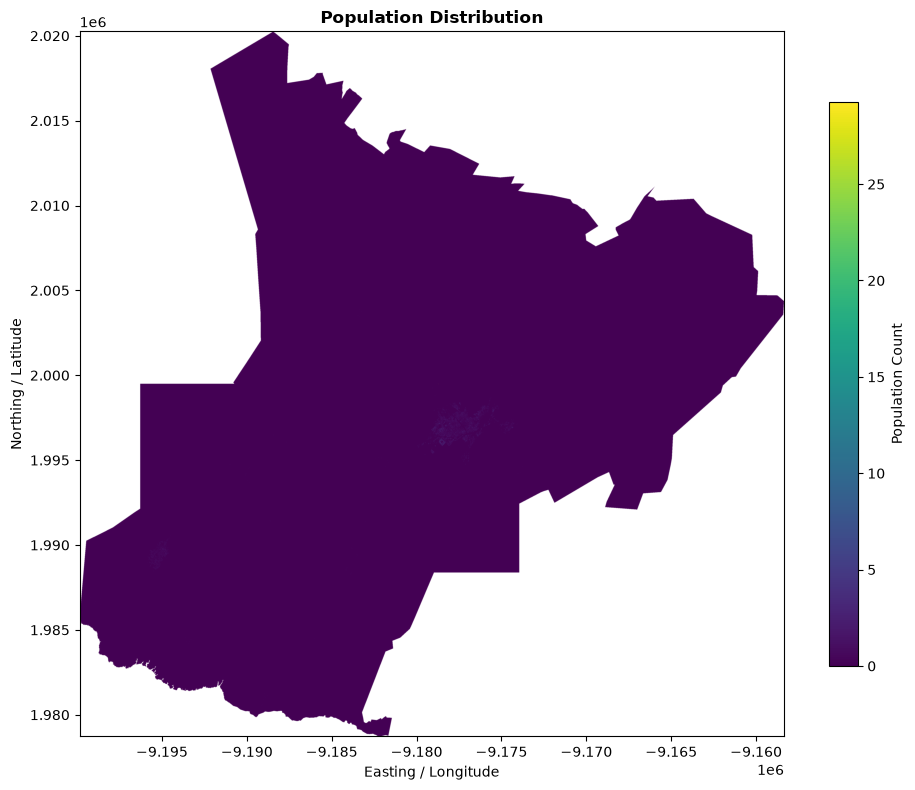

In [226]:
import rasterio as rio
from rasterio.plot import show
import matplotlib.pyplot as plt

# 1. Open the saved GeoTIFF file
with rio.open(population_distribution_path) as src:
    fig, ax = plt.subplots(figsize=(10, 8))

    # 2. Plot using rasterio.plot.show
    im = show(src, ax=ax, cmap="viridis", title="Population Distribution")

    # 3. Add a colorbar using the image artist generated by show()
    fig.colorbar(im.get_images()[0], ax=ax, label="Population Count", shrink=0.8)

    ax.set_xlabel("Easting / Longitude")
    ax.set_ylabel("Northing / Latitude")

    plt.tight_layout()
    plt.show()

# Infraestrucura y equipamiento

In [247]:
# 1. Reproject study area polygon to EPSG:4326 (WGS 84) required by OSM
sa_wgs84 = sa_gpd_projected.to_crs(epsg=4326)

# Extract the unified polygon geometry from the GeoDataFrame
polygon = sa_wgs84.union_all()


# Define tags (OSM key-value pairs)
tags = {"amenity": ["school"]}

# Extract features within a boundary (e.g., place name, bounding box, or polygon)
features_gdf = ox.features_from_polygon(polygon, tags=tags)

# Reproject back to your study area's original projected CRS (e.g. ESRI:54009 or UTM)
features_gdf = features_gdf.to_crs(sa_gpd_projected.crs)
print(f"Extracted {len(features_gdf)} features.")

# Save to GIS format
osm_features_path = os.path.join(POP_DISTRIBUTION_OUTPUT_FOLDER, f"osm_features_{study_area}.gpkg")
features_gdf.to_file(osm_features_path, driver="GPKG")

Extracted 6 features.


In [246]:
features_gdf.head(5)

geometry amenity  \
element id                                                                     
way     409529998  POLYGON ((-9183234.444 2003667.844, -9183209.6...  school   
        525689888  POLYGON ((-9178017.989 1997729.837, -9177932.4...  school   
        525689889  POLYGON ((-9177422.638 1996762.664, -9177460.6...  school   
        525689890  POLYGON ((-9177479.239 1997476.386, -9177456.4...  school   
        525707894  POLYGON ((-9178256.296 1996008.176, -9178029.5...  school   

                                                                name  
element id                                                            
way     409529998  Escuela Primaria Rural Federal Hermenegildo Ga...  
        525689888                                                NaN  
        525689889                                                NaN  
        525689890                                                NaN  
        525707894                                                NaN

# Proximidades

In [250]:
# 1. Load the OSM points layer
points_gdf = gpd.read_file(osm_features_path)

# 2. Check CRS and reproject to match your projected study area (metric system)
# If sa_gpd_projected exists, match its CRS directly:
points_proj = points_gdf.to_crs(sa_gpd_projected.crs)

# Alternatively, if sa_gpd_projected is not loaded, reproject to an appropriate metric CRS:
# points_proj = points_gdf.to_crs("ESRI:54009")  # World Mollweide (meters)

# 3. Create 500m buffers around each point geometry
# The buffer distance is in the units of the CRS (meters)
buffer_500m = points_proj.copy()
buffer_500m["geometry"] = points_proj.geometry.buffer(500)

# 4. Optional: Dissolve overlapping buffer boundaries into a single continuous polygon
dissolved_buffer = buffer_500m.dissolve()

# 5. Save buffers back to disk
buffers_path = os.path.join(POP_DISTRIBUTION_OUTPUT_FOLDER, f"osm_buffers_{study_area}.gpkg")
dissolved_buffer.to_file(buffers_path, driver="GPKG")

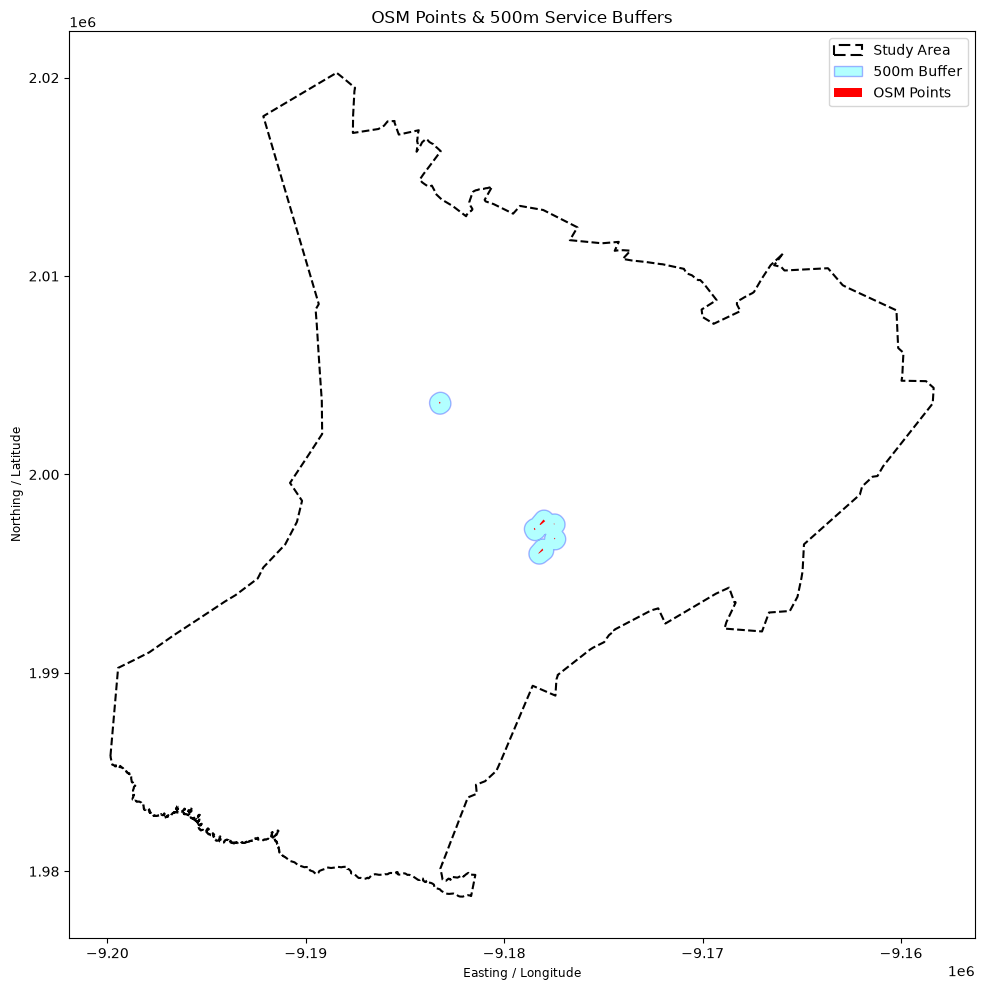

In [252]:
import matplotlib.pyplot as plt

# 1. Set up Matplotlib figure and axis
fig, ax = plt.subplots(figsize=(10, 10))

# 2. Plot Study Area Boundary (Background)
sa_gpd_projected.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.5,
    linestyle="--",
    label="Study Area"
)

# 3. Plot 500m Buffers (Semi-transparent polygons)
dissolved_buffer.plot(
    ax=ax,
    facecolor="cyan",
    edgecolor="blue",
    alpha=0.3,         # Transparency so underlying layers remain visible
    linewidth=1,
    label="500m Buffer"
)

# 4. Plot Original OSM Points
points_proj.plot(
    ax=ax,
    color="red",
    markersize=15,
    zorder=3,          # Keep points on top of buffer polygons
    label="OSM Points"
)

# 5. Styling & Layout
ax.set_title("OSM Points & 500m Service Buffers")
ax.set_xlabel("Easting / Longitude")
ax.set_ylabel("Northing / Latitude")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Analisis de cobertura

In [254]:

# 1. Ensure dissolved_buffer is in the exact same CRS as the raster
with rio.open(population_distribution_path ) as src:
    raster_crs = src.crs

dissolved_buffer_proj = dissolved_buffer.to_crs(raster_crs)

# 2. Compute zonal statistics (sum of raster pixels inside buffer geometry)
stats = zonal_stats(
    dissolved_buffer_proj,
    population_distribution_path,
    stats=["sum", "count", "mean"],
    nodata=np.nan
)

# 3. Extract and print total served population
served_population = stats[0]["sum"]
pixel_count = stats[0]["count"]

print(f"Total Served Population (inside 500m buffer): {served_population:,.2f}")
print(f"Total Pixels Covered: {pixel_count:,}")

Total Served Population (inside 500m buffer): 17,268.66
Total Pixels Covered: 48,209
